<a href="https://colab.research.google.com/github/RiabtsevaAnne/lab/blob/main/%22%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D0%A0%D1%8F%D0%B1%D1%86%D0%B5%D0%B2%D0%B0_%D0%93_%D0%A0_4_9_26_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 5 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
print(os.listdir(path))
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df.head()

NameError: name 'path' is not defined

In [3]:
import kagglehub
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [5]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [21]:
df["gender"].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [22]:
df["smoking_history"].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [23]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [24]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [34]:
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [25]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [26]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [27]:
df.drop_duplicates(inplace=True)

In [20]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [28]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

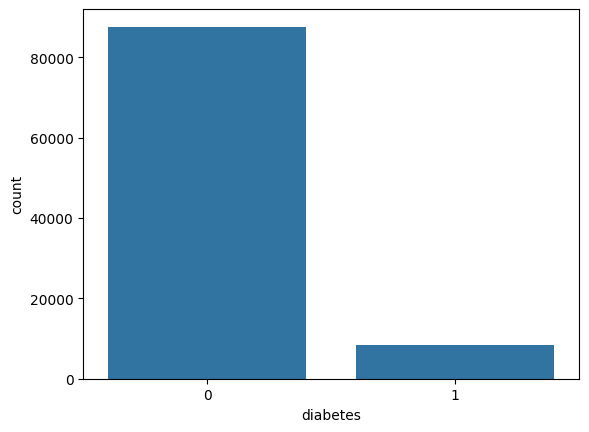

In [29]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [30]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [31]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)

Розмір X_train: (76916, 8)
Розмір X_test: (19230, 8)
Розмір y_train: (76916,)
Розмір y_test: (19230,)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [32]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Дані успішно поділено!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Дані успішно поділено!
X_train: (76916, 8)
X_test: (19230, 8)


In [33]:
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [34]:
X_train = pd.get_dummies(
    X_train,
    columns=["gender", "smoking_history"],
    dtype=int
)
correlations = X_train.corrwith(y_train)
print(correlations.sort_values(ascending=False))

blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
gender_Female                 -0.040533
smoking_history_No Info       -0.113053
dtype: float64


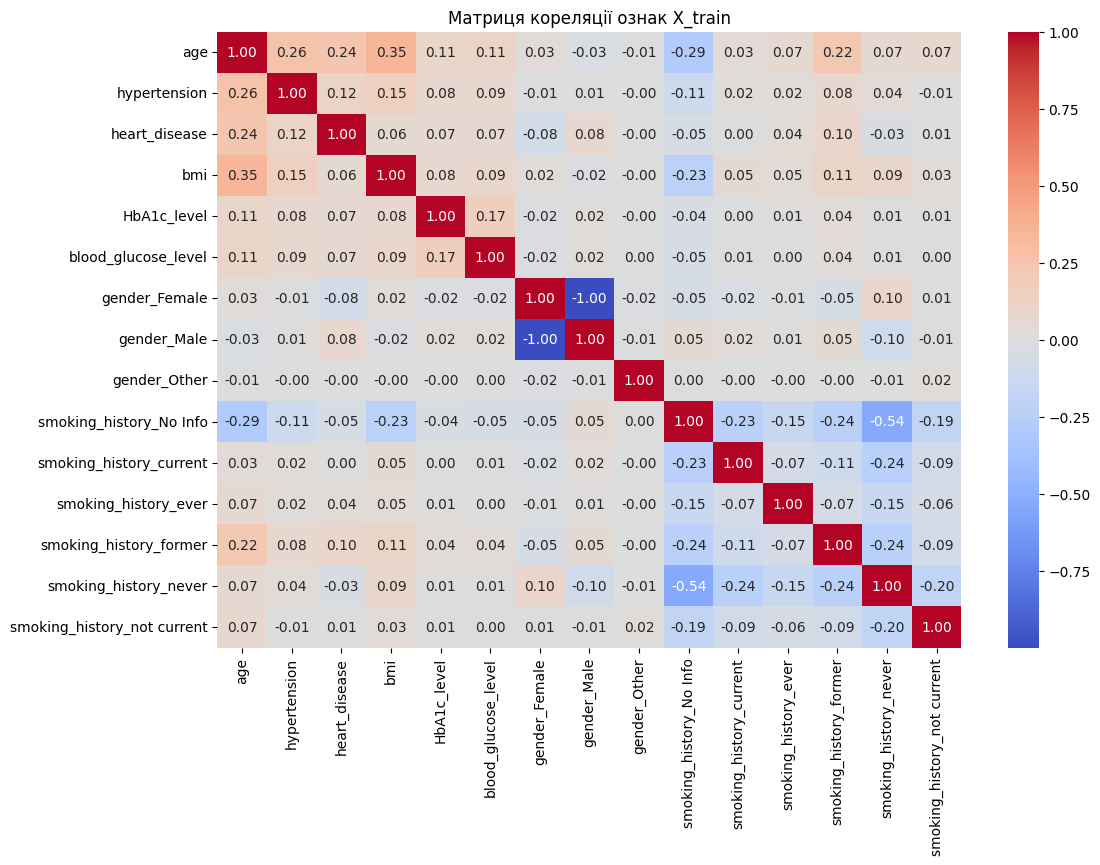

In [35]:
import matplotlib.pyplot as plt
corr_matrix = X_train.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Матриця кореляції ознак X_train")
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

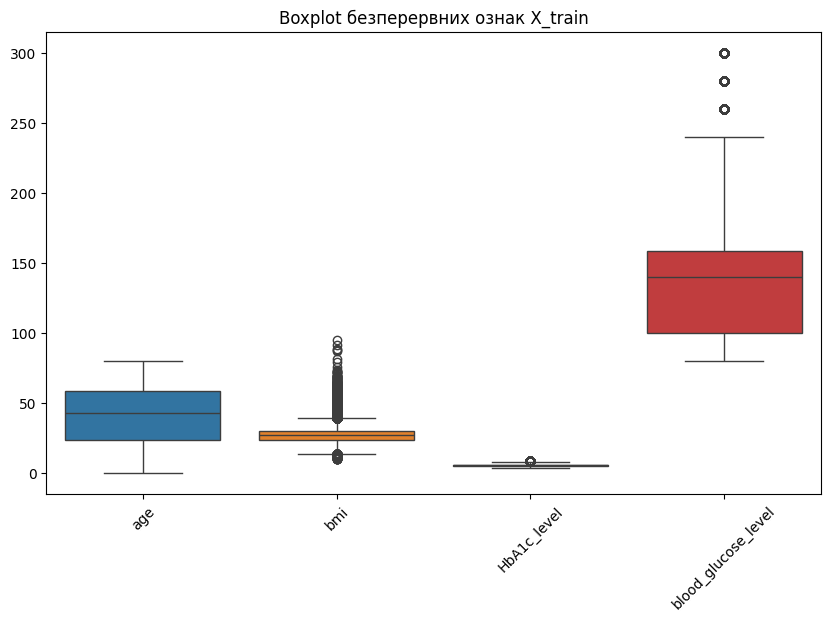

In [36]:
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title("Boxplot безперервних ознак X_train")
plt.xticks(rotation=45)
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [37]:
Q1 = X_train["bmi"].quantile(0.25)
Q3 = X_train["bmi"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Нижня межа:", lower_bound)
print("Верхня межа:", upper_bound)

Q1: 23.39
Q3: 29.85
IQR: 6.460000000000001
Нижня межа: 13.7
Верхня межа: 39.540000000000006


Перевірити асиметрію розподілів ознак **на train**

In [38]:
skewness = X_train[continuous_cols].skew()
print(skewness)

age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [39]:
print("Пропуски в X_train:")
print(X_train.isnull().sum())

print("\nПропуски в X_test:")
print(X_test.isnull().sum())

Пропуски в X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропуски в X_test:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
dtype: int64


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [40]:
X_test = pd.get_dummies(
    X_test, columns=["gender", "smoking_history"], dtype=int
)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [41]:
from imblearn.over_sampling import SMOTE
from collections import Counter
print("До балансування:")
print(Counter(y_train))
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train
)
print("\nПісля балансування:")
print(Counter(y_train_balanced))

До балансування:
Counter({0: 70130, 1: 6786})

Після балансування:
Counter({0: 70130, 1: 70130})


Оголошуємо моделі

In [42]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
models = {
    "LogisticRegression": LogisticRegression(random_state=42),
    "RidgeClassifier": RidgeClassifier(),
    "SGDClassifier": SGDClassifier(random_state=42),
    "SVC": SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: LogisticRegression

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



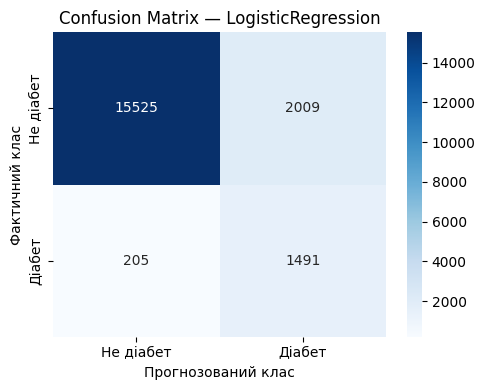


Модель: RidgeClassifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



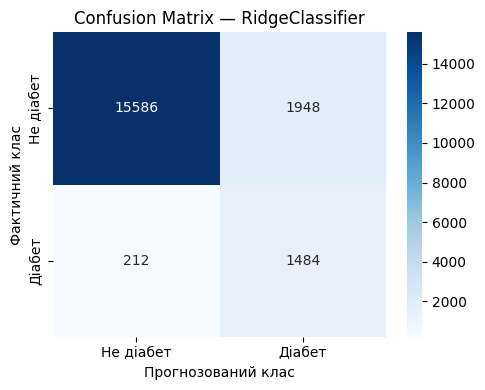


Модель: SGDClassifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



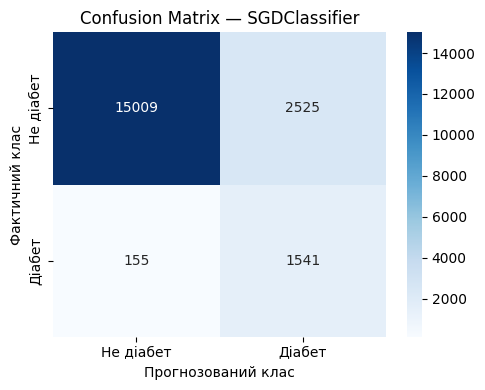

In [ ]:
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_scaled)
    print(f"\n{'=' * 50}")
    print(f"Модель: {name}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Не діабет", "Діабет"],
        yticklabels=["Не діабет", "Діабет"]
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Прогнозований клас")
    plt.ylabel("Фактичний клас")
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [43]:
param_grids = {
    "LogisticRegression": {
        "C": [0.01, 0.1, 1, 10],
        "solver": ["liblinear", "lbfgs"]
    },
    "RidgeClassifier": {
        "alpha": [0.01, 0.1, 1, 10, 100]
    },
    "SGDClassifier": {
        "loss": ["hinge", "log_loss"],
        "penalty": ["l2", "l1", "elasticnet"],
        "alpha": [0.0001, 0.001, 0.01]
    },
    "SVC": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"]
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [44]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [45]:
models = {
    "LogisticRegression": LogisticRegression(random_state=42),
    "RidgeClassifier": RidgeClassifier(),
    "SGDClassifier": SGDClassifier(random_state=42),
    "SVC": SVC(random_state=42)
}
param_grids = {
    "LogisticRegression": {
        "C": [0.01, 0.1, 1, 10],
        "solver": ["liblinear", "lbfgs"]
    },
    "RidgeClassifier": {
        "alpha": [0.01, 0.1, 1, 10, 100]
    },
    "SGDClassifier": {
        "loss": ["hinge", "log_loss"],
        "penalty": ["l2", "l1", "elasticnet"],
        "alpha": [0.0001, 0.001, 0.01]
    },
    "SVC": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"]
    }
}

print("Словники models і param_grids створено.")

Словники models і param_grids створено.


Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [47]:
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"Навчання моделі: {name}")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("classifier", model)
    ])

    param_grid = {
        f"classifier__{param}": values
        for param, values in param_grids[name].items()
    }

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=3,
        scoring="f1",
        min_resources=300,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print("Найкращі параметри:", search.best_params_)
    print(f"F1-score: {search.best_score_:.4f}")

print("\nПошук завершено.")

Навчання моделі: LogisticRegression
Найкращі параметри: {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
F1-score: 0.6098
Навчання моделі: RidgeClassifier
Найкращі параметри: {'classifier__alpha': 100}
F1-score: 0.6587
Навчання моделі: SGDClassifier
Найкращі параметри: {'classifier__alpha': 0.01, 'classifier__loss': 'log_loss', 'classifier__penalty': 'l1'}
F1-score: 0.6304
Навчання моделі: SVC
Найкращі параметри: {'classifier__C': 1, 'classifier__kernel': 'linear'}
F1-score: 0.5892

Пошук завершено.


In [46]:
random_indices = X_test.sample(n=10, random_state=42).index
y_pred = best_model.predict(X_test.loc[random_indices])
results = pd.DataFrame({
    "Індекс": random_indices,
    "Істинний клас": y_test.loc[random_indices].values,
    "Передбачений клас": y_pred
})

print(results.to_string(index=False))

NameError: name 'best_model' is not defined

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop("diabetes", axis=1)
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
X_train = pd.get_dummies(
    X_train, columns=["gender", "smoking_history"], dtype=int
)
X_test = pd.get_dummies(
    X_test, columns=["gender", "smoking_history"], dtype=int
)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?